# Application 3B — a curved boundary, kernels, and scaling

**Question:** How do kernels, C, gamma, and units affect a circular boundary?

Draw 1,200 points uniformly in $[-2,2]^2$. Label +1 inside $x_1^2+x_2^2<1.5$, otherwise −1,
then flip each label independently with probability 0.08. Fit and evaluate these **noisy** labels;
clean labels explain the simulation only.

A **kernel** computes an implicit transformed-space inner product.
For RBF, $K(x,z)=\exp(-\gamma\|x-z\|^2)$: larger gamma makes similarity more local.
C penalizes margin violations; decision scores are not probabilities.

Use stratified 60/20/20 splits. Five-fold training CV selects by balanced accuracy (mean class recall),
with scaling fitted inside every pipeline. Validation audits; test never selects settings.
See [lecture](03_support_vector_machines.pdf) and [solution](Solutions/03_B_kernels_and_scaling_solution.pdf).

## 1. Generate the data and reserve partitions

`default_rng` controls reproducible draws. `train_test_split(..., stratify=y)` approximately preserves label proportions.
`make_pipeline` joins preprocessing with fitting; `StandardScaler` learns means/scales on fitting rows only.
The arrays below contain 720 training, 240 validation, and 240 test rows. The clean label is never an input.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

rng = np.random.default_rng(17)
X = rng.uniform(-2, 2, size=(1200, 2))
clean_label = np.where(np.sum(X ** 2, axis=1) < 1.5, 1, -1)
y = clean_label.copy()
flipped = rng.random(len(y)) < 0.08
y[flipped] *= -1
train_valid_ids, test_ids = train_test_split(np.arange(len(y)), test_size=0.2, random_state=23, stratify=y)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=0.25, random_state=23, stratify=y[train_valid_ids])
assert set(train_ids).isdisjoint(valid_ids) and set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, y_train = X[train_ids], y[train_ids]
X_valid, y_valid = X[valid_ids], y[valid_ids]
X_test, y_test = X[test_ids], y[test_ids]
print("Partition sizes:", len(train_ids), len(valid_ids), len(test_ids))
print("Training positive fraction:", np.mean(y_train == 1))

Partition sizes: 720 240 240
Training positive fraction: 0.30972222222222223


## 2. Verify the polynomial feature map

For standardized z,
$$\phi(z)=(1,\sqrt2z_1,\sqrt2z_2,z_1^2,\sqrt2z_1z_2,z_2^2),\quad
\phi(z)^T\phi(v)=(1+z^Tv)^2.$$
Unweighted polynomial columns span the same functions but change the penalty geometry.

Compare `quadratic_features` plus linear SVC with `SVC(kernel="poly",degree=2,gamma=1,coef0=1)`.
`coef0` is a kernel constant, not the score intercept. Use the same input scaler without rescaling expanded columns.
`dual_coef_` stores signed dual coefficients used to check the kernel-space squared norm and objective.

In [2]:
def quadratic_features(inputs):
    a, b = inputs[:, 0], inputs[:, 1]
    return np.column_stack([np.ones(len(inputs)), np.sqrt(2)*a, np.sqrt(2)*b,
                            a*a, np.sqrt(2)*a*b, b*b])

scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
Z_valid = scaler.transform(X_valid)
Phi = quadratic_features(Z_train)
K = (1 + Z_train @ Z_train.T) ** 2
np.testing.assert_allclose(Phi @ Phi.T, K, atol=1e-10)
explicit = SVC(kernel="linear", C=1, tol=1e-8).fit(Phi, y_train)
implicit = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=1, tol=1e-8).fit(Z_train, y_train)
score_explicit = explicit.decision_function(quadratic_features(Z_valid))
score_implicit = implicit.decision_function(Z_valid)
np.testing.assert_allclose(score_explicit, score_implicit, atol=2e-4)
coef = implicit.dual_coef_[0]
K_support = (1 + implicit.support_vectors_ @ implicit.support_vectors_.T) ** 2
objective_explicit = np.sum(explicit.coef_ ** 2)/2 + np.maximum(0, 1-y_train*explicit.decision_function(Phi)).sum()
objective_implicit = coef @ K_support @ coef/2 + np.maximum(0, 1-y_train*implicit.decision_function(Z_train)).sum()
np.testing.assert_allclose(objective_explicit, objective_implicit, rtol=1e-3)
print("Maximum validation score difference:", np.max(np.abs(score_explicit-score_implicit)))
print("Matched primal objectives:", objective_explicit, objective_implicit)

Maximum validation score difference: 2.637889906509372e-13
Matched primal objectives: 237.49974207160946 237.4997420716089


## 3. Select settings on shared training folds

Compare logistic, linear SVM, explicit quadratic SVM, polynomial SVM, and RBF SVM.
`build_model` creates pipelines; `FunctionTransformer` wraps the fixed map without learning parameters.
`cross_val_score` refits each pipeline, including scaling, in every fold.
Search C=0.01,0.1,1,10; RBF also searches gamma=0.01,0.1,1,10.
Logistic C controls inverse regularization, but logistic and hinge losses differ.

Maximize mean balanced accuracy within each family, then identify the overall CV winner; ties follow loop order.
The heatmap shows the RBF grid. Fold SD is descriptive, not a confidence interval.
C≤10 and SVC tolerance 0.001 keep this teaching search manageable; very large C can slow nearly degenerate fits.

,family,C,gamma,CV balanced accuracy,fold SD
0,Logistic,0.01,1.0,0.500000,0.000000
1,Linear,0.01,1.0,0.500000,0.000000
2,Explicit quadratic,0.10,1.0,0.899253,0.016162
3,Polynomial,0.10,1.0,0.899253,0.016162
4,RBF,10.00,0.1,0.897455,0.013710


Frozen overall family: Explicit quadratic


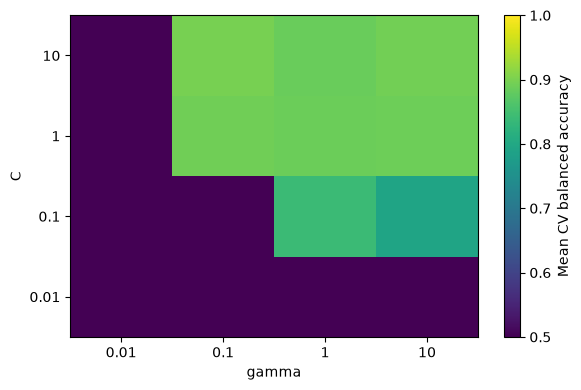

In [3]:
def build_model(family, C, gamma=1):
    if family == "Logistic":
        return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    if family == "Explicit quadratic":
        return make_pipeline(StandardScaler(), FunctionTransformer(quadratic_features),
                             SVC(kernel="linear", C=C, tol=1e-3))
    if family == "Polynomial":
        svc = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=C, tol=1e-3)
    elif family == "RBF":
        svc = SVC(kernel="rbf", gamma=gamma, C=C, tol=1e-3)
    else:
        svc = SVC(kernel="linear", C=C, tol=1e-3)
    return make_pipeline(StandardScaler(), svc)

C_values = [0.01, 0.1, 1, 10]
gamma_values = [0.01, 0.1, 1, 10]
families = ["Logistic", "Linear", "Explicit quadratic", "Polynomial", "RBF"]
folds = list(StratifiedKFold(5, shuffle=True, random_state=23).split(X_train, y_train))
rows = []
for family in families:
    for C in C_values:
        for gamma in gamma_values if family == "RBF" else [1]:
            model = build_model(family, C, gamma)
            scores = cross_val_score(model, X_train, y_train, cv=folds, scoring="balanced_accuracy")
            rows.append({"family": family, "C": C, "gamma": gamma,
                         "CV balanced accuracy": scores.mean(), "fold SD": scores.std(ddof=1)})
cv_results = pd.DataFrame(rows)
best_rows = cv_results.loc[cv_results.groupby("family", sort=False)["CV balanced accuracy"].idxmax()]
selected_family = best_rows.loc[best_rows["CV balanced accuracy"].idxmax(), "family"]
models = {}
for _, row in best_rows.iterrows():
    models[row["family"]] = build_model(row["family"], float(row["C"]), float(row["gamma"])).fit(X_train, y_train)
display(best_rows.reset_index(drop=True))
print("Frozen overall family:", selected_family)
rbf_grid = cv_results[cv_results["family"] == "RBF"].pivot(index="C", columns="gamma", values="CV balanced accuracy")
plt.figure(figsize=(6, 4))
plt.imshow(rbf_grid.to_numpy(), origin="lower", aspect="auto", vmin=0.5, vmax=1)
plt.xticks(range(len(gamma_values)), gamma_values); plt.yticks(range(len(C_values)), C_values)
plt.xlabel("gamma"); plt.ylabel("C"); plt.colorbar(label="Mean CV balanced accuracy")
plt.tight_layout(); plt.show()

## 4. Inspect boundaries and change units

Plots use training rows and fixed grid points; circles mark support vectors (none for logistic).
Two extra RBF settings are prespecified diagnostics, not newly selected candidates.
The dashed circle is the clean boundary. `decision_function` supplies scores; `contour(levels=[0])` draws boundaries.

Multiply x1 by 100: unscaled RBF distances change. Refit `StandardScaler` on rescaled training rows
and check validation-score agreement with the original standardized model, keeping C/gamma fixed.

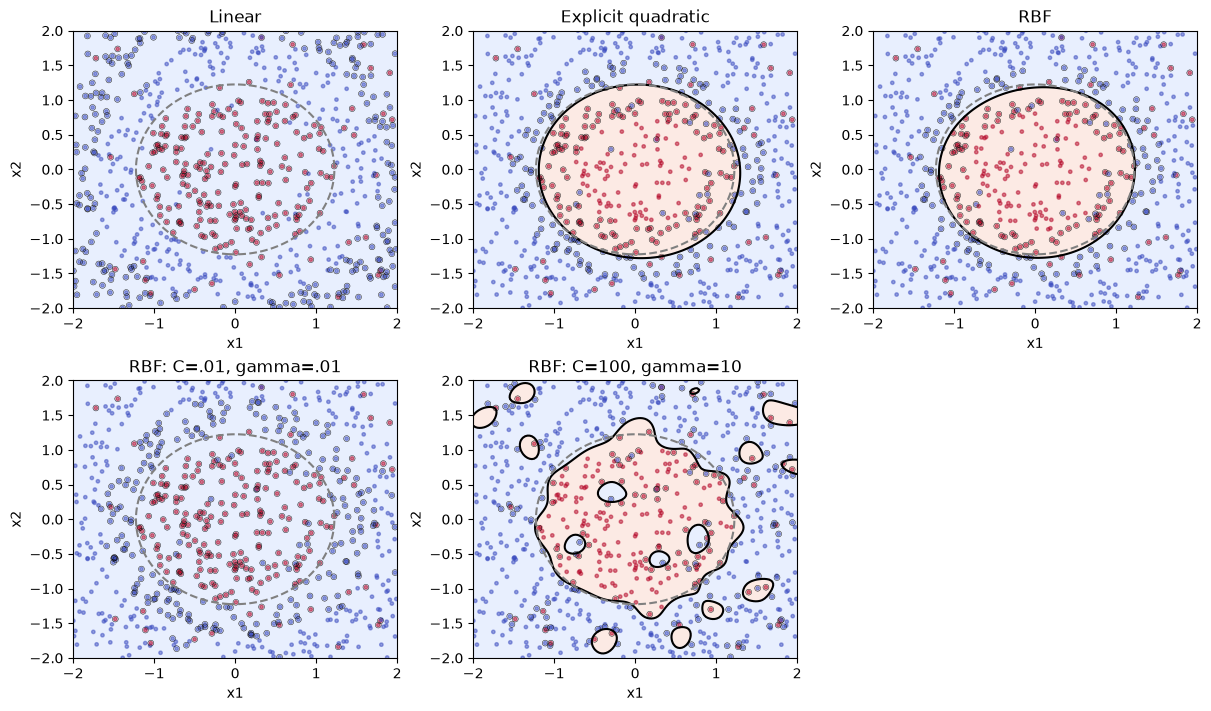

,fit,validation balanced accuracy
0,Raw original units,0.874552
1,Raw changed units,0.729567
2,Scaled original units,0.871540
3,Scaled changed units,0.871540


In [4]:
xx, yy = np.meshgrid(np.linspace(-2, 2, 150), np.linspace(-2, 2, 150))
grid = np.column_stack([xx.ravel(), yy.ravel()])
panels = [(name, models[name]) for name in ["Linear", "Explicit quadratic", "RBF"]]
panels += [("RBF: C=.01, gamma=.01", build_model("RBF", .01, .01).fit(X_train, y_train)),
           ("RBF: C=100, gamma=10", build_model("RBF", 100, 10).fit(X_train, y_train))]
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, (name, model) in zip(axes.ravel(), panels):
    scores = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, scores >= 0, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.2)
    if scores.min() < 0 < scores.max():
        ax.contour(xx, yy, scores, levels=[0], colors="black")
    ax.contour(xx, yy, xx**2 + yy**2, levels=[1.5], colors="gray", linestyles="--")
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=6, alpha=0.5)
    sv = model.named_steps["svc"].support_
    ax.scatter(X_train[sv, 0], X_train[sv, 1], facecolors="none", edgecolors="black", s=18, linewidths=0.3)
    ax.set(title=name, xlabel="x1", ylabel="x2")
axes.ravel()[-1].set_visible(False)
plt.show()

best_rbf = best_rows[best_rows["family"] == "RBF"].iloc[0]
C_rbf, gamma_rbf = float(best_rbf["C"]), float(best_rbf["gamma"])
unit_change = np.array([100.0, 1.0])
raw_original = SVC(C=C_rbf, gamma=gamma_rbf).fit(X_train, y_train)
raw_changed = SVC(C=C_rbf, gamma=gamma_rbf).fit(X_train*unit_change, y_train)
scaled_changed = build_model("RBF", C_rbf, gamma_rbf).fit(X_train*unit_change, y_train)
np.testing.assert_allclose(models["RBF"].decision_function(X_valid),
                           scaled_changed.decision_function(X_valid*unit_change), atol=1e-4)
scaling_rows = []
for name, model, inputs in [("Raw original units", raw_original, X_valid),
                            ("Raw changed units", raw_changed, X_valid*unit_change),
                            ("Scaled original units", models["RBF"], X_valid),
                            ("Scaled changed units", scaled_changed, X_valid*unit_change)]:
    prediction = np.where(model.decision_function(inputs) >= 0, 1, -1)
    scaling_rows.append({"fit": name, "validation balanced accuracy": balanced_accuracy_score(y_valid, prediction)})
display(pd.DataFrame(scaling_rows))

## 5. Evaluate frozen models

Validation only audits. Test reports accuracy, balanced accuracy, and score-based ROC AUC (ranking, not calibration).
A constant majority-baseline score has AUC 0.5. `support_` identifies training supports, not difficult test rows.
Matched explicit-map/polynomial settings should agree closely; small solver differences do not refute equivalence.

**Explain:** Why does a line miss the circle? What does very local RBF similarity do?
Do more supports imply better prediction? Why evaluate noisy rather than clean labels?

In [5]:
validation_rows = []
for name, model in models.items():
    score = model.decision_function(X_valid)
    validation_rows.append({"model": name, "validation balanced accuracy":
                            balanced_accuracy_score(y_valid, np.where(score >= 0, 1, -1))})
display(pd.DataFrame(validation_rows))
classes, counts = np.unique(y_train, return_counts=True)
majority = classes[counts.argmax()]
test_rows = [{"model": "Majority baseline", "accuracy": np.mean(y_test == majority),
              "balanced accuracy": balanced_accuracy_score(y_test, np.full(len(y_test), majority)),
              "ROC AUC": 0.5, "support vectors": None}]
for name, model in models.items():
    scores = model.decision_function(X_test)
    pred = np.where(scores >= 0, 1, -1)
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, pred),
                     "balanced accuracy": balanced_accuracy_score(y_test, pred),
                     "ROC AUC": roc_auc_score(y_test == 1, scores),
                     "support vectors": len(model.named_steps["svc"].support_) if "svc" in model.named_steps else None})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results)
print("The family chosen before test evaluation remains:", selected_family)

,model,validation balanced accuracy
0,Logistic,0.50000
1,Linear,0.50000
2,Explicit quadratic,0.87154
3,Polynomial,0.87154
4,RBF,0.87154


,accuracy,balanced accuracy,ROC AUC,support vectors
model,,,,
Majority baseline,0.691667,0.500000,0.500000,NaN
Logistic,0.691667,0.500000,0.503256,NaN
Linear,0.691667,0.500000,0.463937,447.0
Explicit quadratic,0.895833,0.879762,0.917698,285.0
Polynomial,0.895833,0.879762,0.917698,285.0
RBF,0.908333,0.892543,0.917128,247.0


The family chosen before test evaluation remains: Explicit quadratic


**Documentation reference:** [scikit-learn 1.8 SVM guide](https://scikit-learn.org/1.8/modules/svm.html).